# Bar Chart Race (animated ranking)

**Family:** Interactive, animated & big data &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Interactive, animated & big data:* What-if sliders, linked views, animation and million-point rendering. Use these when exploration or motion adds understanding that a static chart cannot.

## Design purpose

An animated, re-sorting horizontal bar chart. Each frame shows the top N items at one moment, and bars overtake each other as time advances. Motion turns rank changes into a story: who rose, who fell, and when the leader changed.

## When to use

- Tell a "who led when" story in a presentation or social post, where motion holds attention
- Show rank changes among many entities over a long period (market caps, brands, countries)
- Hook the audience before a detailed static analysis

## Avoid when

- Readers need to compare values precisely between two dates (use a slope or bump chart)
- The output is a printed report or PDF (a single frame loses the story)
- Ranks barely change (a static sorted bar is clearer)

## Alternatives

- Bump chart (ranks over time, static)
- Slope chart (two dates)
- Small multiples of sorted bars at key dates

## Design tips

- Keep each entity's color fixed across frames; color follows the entity, never the rank
- Give named colors only to the few entities that matter (≤ 8 hues) and gray the rest
- Interpolate between data points so bars glide instead of jumping
- Show the date large and quiet in a corner; note that the axis rescales each frame
- Pair it with a static chart that readers can study

## Example

Simulated market capitalisation (US$ bn) of 15 fictional companies, 2005–2024, interpolated to 39 frames, including a 2008 crash and the rise of two tech challengers.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.animation import FuncAnimation

### Data

In [2]:
rng = np.random.default_rng(21)
years = np.arange(2005, 2025)
companies = {  # name: (2005 market cap $bn, mean annual growth)
    "Meridian Oil": (450, -0.01), "Globex Industrial": (380, 0.03), "Kestrel Bank": (300, 0.04),
    "Delta Retail": (260, 0.05), "Nova Telecom": (240, 0.02), "Evergreen Pharma": (220, 0.06),
    "Apex Systems": (200, 0.09), "Blue Harbor Insurance": (180, 0.05), "Cobalt Energy": (160, 0.03),
    "Juniper Motors": (120, 0.08), "Lumen Media": (110, 0.04), "Fintrex Payments": (60, 0.15),
    "Northwind Logistics": (90, 0.06), "Helix Semis": (40, 0.22), "Ionix Cloud": (15, 0.30),
}
start = np.array([v[0] for v in companies.values()])
growth = np.array([v[1] for v in companies.values()])
shocks = rng.normal(0, 0.12, (len(years), len(companies)))
shocks[years == 2008] -= 0.40           # financial crisis
shocks[years == 2020] -= 0.10           # pandemic dip
log_cap = np.log(start) + np.cumsum(np.vstack([np.zeros(len(companies)), (growth + shocks)[1:]]), axis=0)
df = pd.DataFrame(np.exp(log_cap), index=years, columns=list(companies)).round(1)

# Interpolate two in-between frames per year so bars glide.
steps = 2
df.index = df.index.astype(float)
frames = df.reindex(np.linspace(years[0], years[-1], (len(years) - 1) * steps + 1)).interpolate("index")
df.tail(3).T.sort_values(2024.0, ascending=False).head(10)

,2022.0,2023.0,2024.0
Ionix Cloud,909.0,1395.2,1850.2
Helix Semis,643.5,807.2,1068.4
Evergreen Pharma,522.7,506.2,618.4
Fintrex Payments,456.8,494.1,572.6
Apex Systems,392.3,412.9,380.7
Blue Harbor Insurance,283.6,302.2,374.5
Kestrel Bank,314.5,304.2,352.6
Juniper Motors,297.6,335.8,334.1
Nova Telecom,316.0,362.6,294.7
Delta Retail,243.3,265.0,273.8


### Plot

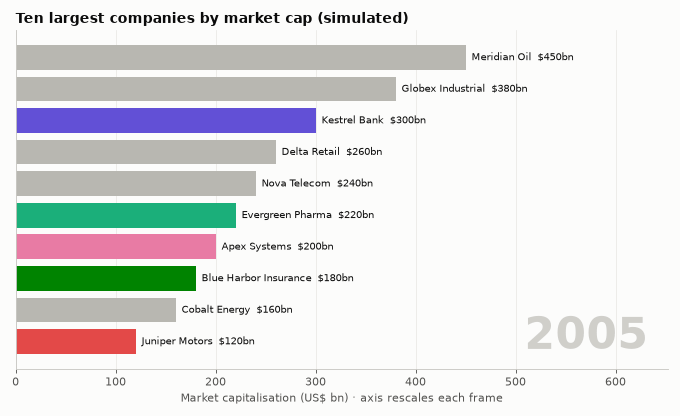

In [3]:
# Fixed color per entity: the 8 largest at the end get the categorical hues, everyone else gray.
leaders = df.iloc[-1].sort_values(ascending=False).index[:8]
colors = {name: GRAY for name in df.columns} | {name: PALETTE[i] for i, name in enumerate(leaders)}

fig, ax = plt.subplots(figsize=(8.5, 5.2))


def draw(i):
    ax.clear()
    row = frames.iloc[i].sort_values().tail(10)
    ax.barh(range(10), row.values, color=[colors[n] for n in row.index], height=0.78)
    for y, (name, value) in enumerate(row.items()):
        ax.text(value, y, f"  {name}  ${value:,.0f}bn", va="center", fontsize=9, color="#0b0b0b")
    ax.set_xlim(0, row.max() * 1.45)
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Market capitalisation (US$ bn) · axis rescales each frame")
    ax.set_title("Ten largest companies by market cap (simulated)")
    ax.text(0.97, 0.06, f"{int(frames.index[i])}", transform=ax.transAxes, ha="right",
            fontsize=40, fontweight="bold", color="#d0cfca")


anim = FuncAnimation(fig, draw, frames=len(frames), interval=170)
draw(len(frames) - 1)  # the static preview shows the final year
fig.tight_layout()
plt.close(fig)  # show the animation instead of the last frame
anim.save("bar_chart_race.gif", writer="pillow", fps=6, dpi=80)
from IPython.display import Image
Image("bar_chart_race.gif")

## How to read it

Watch Ionix Cloud and Helix Semis climb from outside the top ten to the top two, while the old energy and industrial leaders slide down. The x-axis rescales every frame, so compare positions, not absolute bar lengths, across years.

---
Standalone script: [`bar_chart_race.py`](bar_chart_race.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)